# 01 — Exploratory Data Analysis

**Dataset:** Kaggle House Prices, Ames housing (`data/raw/train.csv`)

Goal of this notebook: *look at the data before touching it.* Every section ends
with a written finding, not just a plot. These findings drive Tuesday's
feature pipeline.

- Shape: **1460 rows × 81 columns**, target = `SalePrice`
- Companion docs: `data/raw/data_description.txt` (what every column means)

## 1. Dataset audit

First contact: how big, what types, what's missing. Note how we read the CSV —
`NA` is a *literal string* in this dataset and often means "this house has no
such feature" (no pool, no garage), not "value unknown". Pandas converts it to
`NaN` automatically, which is convenient for counting but we must remember what
it *means* when we impute on Tuesday.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/train.csv")  # path relative to notebooks/
print(f"shape: {df.shape}")
df.head(3)

shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [2]:
print(df.dtypes.value_counts())
print("\nid columns:", [c for c in df.columns if "id" in c.lower()])

str        43
int64      35
float64     3
Name: count, dtype: int64

id columns: ['Id']


## 2. Missingness

19 of 81 columns have missing values. The pattern matters
more than the count: columns that miss *together* usually describe one feature
of the house (garage, basement, pool) — and in this dataset a block of `NA`
usually means **"the house doesn't have that feature"** (see
`data_description.txt`: e.g. `PoolQC`: "NA = No Pool").

That changes Tuesday's strategy: for these, `NaN` should become its own
informative category ("no pool"), *not* be filled with the median. Only truly
unknown numeric values (like `LotFrontage`) deserve median imputation.

In [3]:
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
miss_pct = (miss / len(df) * 100).round(1)
miss_table = pd.DataFrame({"missing": miss, "pct": miss_pct})
miss_table

,missing,pct
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


**Top of the table (full table in the cell output):** `PoolQC`, `MiscFeature`,
`Alley`, `Fence`, `FireplaceQu` are missing for 99.5%–47.3% of houses —
these are *absence*, not unknowns. `LotFrontage` (17.7%) and
`GarageYrBlt` (5.5%) sit in the garage/frontage families where
`NA` again means "no garage" / corner-lot quirks. `Electrical` is the only
column missing a trivial number (1 row) — that one really is an unknown.

## 3. The target: to log or not to log

OLS squares its errors, so it cares a lot about the *shape* of the target.
A right-skewed target (a long tail of expensive houses) means big errors on
expensive homes dominate the fit. The standard fix: model `log1p(SalePrice)`
instead, which pulls the tail in. This is the single most consequential
decision of the week — Kaggle even scores this competition on the log scale
(RMSLE).

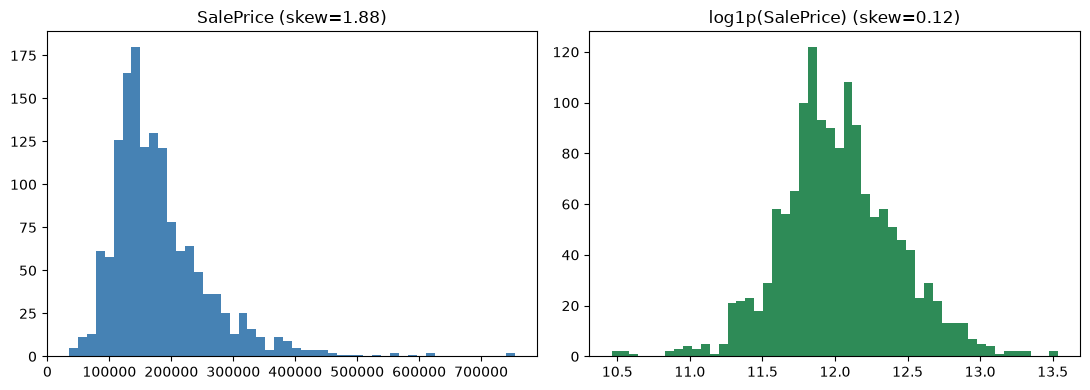

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["SalePrice"], bins=50, color="steelblue")
axes[0].set_title(f"SalePrice (skew={df['SalePrice'].skew():.2f})")

axes[1].hist(np.log1p(df["SalePrice"]), bins=50, color="seagreen")
axes[1].set_title(f"log1p(SalePrice) (skew={np.log1p(df['SalePrice']).skew():.2f})")
plt.tight_layout()

**Decision: model `log1p(SalePrice)`.** Raw skew = **1.88**
(long right tail); after log1p skew = **0.12** — near-symmetric.
Kurtosis drops from 6.54 to 0.81. Every fit this week uses
the log target, and we `expm1` back to dollars only at submission time.

## 4. Feature landscape

Three questions, in order of importance:

1. **Which features correlate with price?** — what signal exists at all
2. **Which features are collinear with each other?** — OLS hates redundancy;
   correlated columns inflate each other's coefficient variance
3. **Which features are skewed?** — skewed inputs often want the same
   log treatment as the target

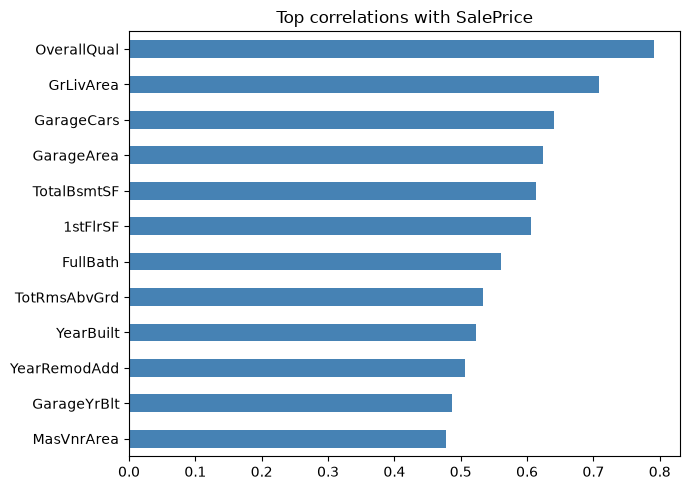

In [5]:
num = df.select_dtypes(include=[np.number]).drop(columns=["Id"])
corr_with_price = num.drop(columns=["SalePrice"]).corrwith(df["SalePrice"]).sort_values()
corr_with_price.tail(12).plot.barh(figsize=(7, 5), color="steelblue")
plt.title("Top correlations with SalePrice")
plt.tight_layout()

**Finding — the quality/area axis dominates.** Top correlates: overall
quality, living area, garage capacity/area, basement and first-floor area,
bathrooms. All are things a home buyer would name. The signal is sane — no
surprise features leaking the answer.

In [6]:
# pairwise correlations inside the families that matter
pairs = [
    ("GarageCars", "GarageArea"),
    ("TotalBsmtSF", "1stFlrSF"),
    ("GrLivArea", "TotRmsAbvGrd"),
    ("OverallQual", "YearBuilt"),
]
for a, b in pairs:
    print(f"{a:>14} vs {b:<14} r = {num[a].corr(num[b]):.2f}")

    GarageCars vs GarageArea     r = 0.88
   TotalBsmtSF vs 1stFlrSF       r = 0.82
     GrLivArea vs TotRmsAbvGrd   r = 0.83
   OverallQual vs YearBuilt      r = 0.57


**Finding — collinearity clusters confirmed.** GarageCars↔GarageArea
r = 0.88 (a garage that fits 2 cars *is* bigger), TotalBsmtSF↔1stFlrSF
r = 0.82 (basement usually mirrors the footprint above),
GrLivArea↔TotRmsAbvGrd r = 0.83 (bigger homes have more rooms),
OverallQual↔YearBuilt r = 0.57 (newer homes are rated better).

OLS doesn't know these are duplicates — it splits credit between them
unstably. Friday's spec comparison will try dropping one from each pair.

In [7]:
skew_table = num.drop(columns=["SalePrice"]).skew().sort_values(ascending=False)
print(skew_table.head(12).round(2))

MiscVal          24.48
PoolArea         14.83
LotArea          12.21
3SsnPorch        10.30
LowQualFinSF      9.01
KitchenAbvGr      4.49
BsmtFinSF2        4.26
ScreenPorch       4.12
BsmtHalfBath      4.10
EnclosedPorch     3.09
MasVnrArea        2.67
OpenPorchSF       2.36
dtype: float64


**Finding — heavy right skew in the count/area features.** Most skewed:
MiscVal, PoolArea, LotArea, 3SsnPorch, LowQualFinSF, KitchenAbvGr, BsmtFinSF2, ScreenPorch (skews 24.5 down to
4.1). These want a `log1p` transform so a few mansions
don't bend the fitted line. Zero-inflated features (`PoolArea`, `3SsnPorch`)
keep their zeros under log1p, which is exactly what we want.

## 5. Findings summary — what Tuesday builds

- **Target:** model `log1p(SalePrice)` (skew 1.88 → 0.12); `expm1` only at submission.
- **Imputation, two kinds:**
  - *Absence* (`PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, all `Garage*`/`Bsmt*` when the house has none) → encode "absent" as its own category, not a median.
  - *Unknown* (`LotFrontage`, `MasVnrArea`, `Electrical`) → median/mode is honest.
- **Ordinal mappings:** quality columns (`ExterQual`, `BsmtQual`, `KitchenQual`, `HeatingQC`, …) are strings like Ex/Gd/TA/Fa/Po — map to 5..1, absent = 0. Cheap, huge signal (OverallQual is the top correlate).
- **Skewed numerics:** log1p the top-skewed area/count features.
- **Collinearity watch-list for Friday:** drop one of each pair — (GarageCars, GarageArea), (TotalBsmtSF, 1stFlrSF), (GrLivArea, TotRmsAbvGrd).